In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np

from config import get_device, WAV_INPUT_DIR, WHISPER_TRANSCRIPTS_DIR
from whisper_transcripts import get_transcript
from items import WhisperTranscript

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



In [7]:
TO_TRANSCRIBE = list(WAV_INPUT_DIR.iterdir())
print(len(TO_TRANSCRIBE))
TO_TRANSCRIBE

9


[PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch7-9.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch15-19.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch10-12.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch23-25.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch1-3.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch4-6.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch26-27.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/a

In [9]:
WAV = TO_TRANSCRIBE[0]
WAV

PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav')

### Transcribe

In [5]:
device = get_device()
device

'cuda'

In [ ]:
res = get_transcript(
    audio=str(WAV),
    model_size="large-v2",
    device=device,
    initial_prompt=None,
    fp16=False,
    language="fr",
    do_vad=False,
)

### Load result

In [46]:
ready_files = list(WHISPER_TRANSCRIPTS_DIR.iterdir())
print(len(ready_files))
ready_files

9


[PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch13-14_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch4-6_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch20-22_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch10-12_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch7-9_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch26-27_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch1-3_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch15-19_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch23-25_whisper_base.json')]

<Axes: >

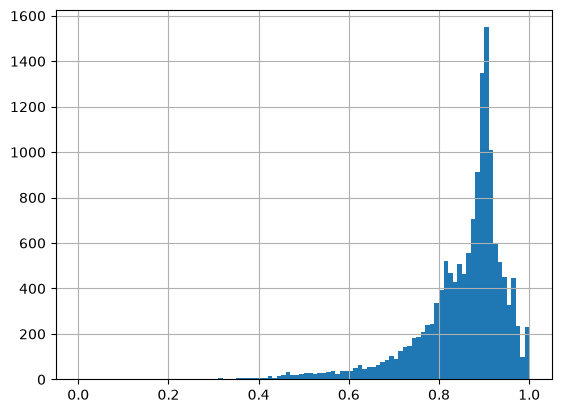

In [54]:
df = []

for rf in ready_files:
    wav_name = rf.stem
    wav_name = wav_name.split("_whisper_")[0]
    res = WhisperTranscript.from_wav_path(wav_name, 'large-v2')
    for s in res.whisper_result['segments']:
        for w in s['words']:
            w['file'] = wav_name
            df.append(w)
df = pd.DataFrame(df)
df.confidence.hist(bins=np.arange(0, 1.01, 0.01))

In [55]:
df

,text,start,end,confidence,file
0,La,1.02,3.18,0.805,ch13-14
1,quatrième,3.18,3.84,0.961,ch13-14
2,planète,3.84,4.46,0.936,ch13-14
3,était,4.46,4.82,0.741,ch13-14
4,celle,4.82,5.20,0.683,ch13-14
...,...,...,...,...,...
14801,si,578.24,578.46,0.760,ch23-25
14802,l'on,578.46,578.64,0.923,ch23-25
14803,s'est,578.64,578.80,0.881,ch23-25
14804,laissé,578.80,579.04,0.955,ch23-25


In [35]:
df.groupby('file').confidence.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
file,,,,,,,,
ch1-3,1490.0,0.89,0.16,0.10,0.85,0.97,0.99,1.0
ch10-12,1669.0,0.87,0.18,0.16,0.81,0.96,0.99,1.0
ch13-14,1375.0,0.89,0.17,0.15,0.87,0.97,0.99,1.0
ch15-19,1878.0,0.85,0.19,0.10,0.76,0.94,0.98,1.0
ch20-22,1667.0,0.88,0.17,0.09,0.83,0.96,0.99,1.0
ch23-25,1443.0,0.86,0.18,0.17,0.78,0.95,0.99,1.0
ch26-27,1663.0,0.89,0.16,0.16,0.87,0.97,0.99,1.0
ch4-6,1646.0,0.88,0.16,0.20,0.84,0.96,0.99,1.0
ch7-9,2015.0,0.89,0.16,0.10,0.86,0.97,0.99,1.0


In [32]:
df.file.value_counts().sort_index()

file
ch1-3      1490
ch10-12    1669
ch13-14    1375
ch15-19    1878
ch20-22    1667
ch23-25    1443
ch26-27    1663
ch4-6      1646
ch7-9      2015
Name: count, dtype: int64